# Voting / ensemble gray-white DEG marker dot plots

기존 Top-10 voting과 fit-score-weighted ensemble의 **영역 라벨을 그대로** 사용하여 각각 white vs gray의 DEG를 구하고 두 개의 dot plot을 만듭니다. Voting 동률은 기존 파일의 fit-rank 순서에 따른 tie-break를 그대로 유지합니다. 영역 밖 label은 제외하며, 발현량 0인 세포는 포함합니다.

1,000개 측정 유전자의 세포별 count 합으로 10,000에 정규화한 뒤 log1p한 값에 대해 양측 Mann–Whitney U 검정(동률 보정)을 수행하고, 각 비교의 전체 1,000개 유전자에 대해 BH 보정합니다. 상수 유전자의 p값은 1로 처리합니다. log2FC는 정규화 count 평균의 비율에 pseudocount 1을 더하여 계산하며 white/gray 방향입니다. 두 방향 각각에서 **사전에 선택한 세포유형 마커 5개**가 조정 p < 0.05, |log2FC| > 1, 적어도 한 영역에서 양성률 ≥ 10%인지 확인합니다. 순서는 각 방향의 log2FC 기준입니다. 이는 상위 5개 전체 DEG가 아니라 생물학적 후보 중 선택한 예시입니다.

점 크기: 원본 count > 0인 세포 비율; 색: 모든 세포의 평균 log1p 정규화 발현량. 두 그림은 같은 색 범위를 사용합니다. Neuronal과 oligodendrocyte/myelin 마커는 각각 세포 유형을 나타내며 영역에 절대적으로 특이적이지 않습니다. 샘플/생물학적 반복이 없고 공간적으로 인접한 세포는 독립 반복이 아니므로 검정의 p값은 **탐색적 세포 수준 통계**입니다. 패널 구성, 세포 조성, 검출률, 공간 의존성의 영향을 받으므로 독립적인 조직 검증 없이 확증적 DEG 또는 정합 증거로 해석할 수 없습니다.

마커 배경: [피질 세포 마커 (SLC17A7, CAMK2A, MOBP)](https://www.nature.com/articles/s41598-026-51501-2), [CNS glia/myelin 표지자](https://pmc.ncbi.nlm.nih.gov/articles/PMC10043115/), [MYRF의 myelination 조절](https://pmc.ncbi.nlm.nih.gov/articles/PMC3742440/), [Human Protein Atlas: MYRF 및 oligodendrocyte 클러스터](https://www.proteinatlas.org/ENSG00000124920-MYRF/single+cell), [Human Protein Atlas: SYT1](https://www.proteinatlas.org/ENSG00000067715-SYT1/single+cell/brain).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

data_dir = Path("/home/Data_Drive_8TB/kykim/CCF_annotation")
out_dir = Path("/home/Data_Drive_8TB/kykim/0. Jupyter/CCF")
adata = sc.read_h5ad(data_dir / "adata.h5ad")
if not adata.obs_names.is_unique or not adata.var_names.is_unique:
    raise ValueError("Cell IDs and gene names must be unique.")
labels = pd.read_csv(out_dir / "BigBrain_top10_consensus_cell_annotation.csv",
                     dtype={"cell_id": str}).set_index("cell_id")
if not labels.index.is_unique:
    raise ValueError("Duplicate annotation cell IDs.")
missing = adata.obs_names.difference(labels.index)
extra = labels.index.difference(adata.obs_names)
if len(missing) or len(extra):
    raise ValueError(f"Annotation cell IDs: {len(missing)} missing, {len(extra)} extra.")
labels = labels.reindex(adata.obs_names)

X = adata.X.toarray() if hasattr(adata.X, "toarray") else np.asarray(adata.X)
if not np.isfinite(X).all() or (X < 0).any() or not np.equal(X, np.floor(X)).all():
    raise ValueError("Expected finite nonnegative integer transcript counts in adata.X.")
counts = X.astype(np.float32, copy=False)
totals = counts.sum(axis=1, dtype=np.float64)
nonzero = totals > 0
norm = np.zeros_like(counts)
norm[nonzero] = counts[nonzero] * (10_000 / totals[nonzero, None])
lognorm = np.log1p(norm)
print(f"Cells: {adata.n_obs:,}; panel genes: {adata.n_vars:,}; zero-count cells retained: {(~nonzero).sum():,}")
print("Normalization: counts per 10,000 panel transcripts, followed by log1p.")
print("Two-sided cell-level Mann-Whitney U with tie correction; BH across all panel genes per comparison.")

results = {}
for method in ("voting", "ensemble"):
    label = labels[f"{method}_region"]
    if label.isna().any():
        raise ValueError(f"{method} has missing labels.")
    gray = label.eq("Gray matter").to_numpy()
    white = label.eq("White matter").to_numpy()
    if not gray.any() or not white.any():
        raise ValueError(f"{method} must contain both gray and white matter.")
    print(f"\n{method}: gray={gray.sum():,}, white={white.sum():,}, excluded={(~(gray | white)).sum():,}; ties included={labels[f'{method}_tie'].sum():,}")
    pvalues = np.ones(adata.n_vars, dtype=float)
    informative = np.ptp(lognorm[gray | white], axis=0) > 0
    print(f"Constant genes assigned p=1: {(~informative).sum()}")
    for start in range(0, adata.n_vars, 20):
        indices = np.flatnonzero(informative[start:start + 20]) + start
        if not len(indices):
            continue
        x = lognorm[np.ix_(white, indices)]
        y = lognorm[np.ix_(gray, indices)]
        pvalues[indices] = mannwhitneyu(x, y, axis=0, alternative="two-sided", method="asymptotic").pvalue
    if not np.isfinite(pvalues).all():
        raise ValueError(f"{method}: non-finite p-values for variable genes.")
    frac_white = (counts[white] > 0).mean(axis=0)
    frac_gray = (counts[gray] > 0).mean(axis=0)
    mean_white = norm[white].mean(axis=0, dtype=np.float64)
    mean_gray = norm[gray].mean(axis=0, dtype=np.float64)
    result = pd.DataFrame({
        "gene": adata.var_names,
        "p_value": pvalues,
        "p_adj_bh": multipletests(pvalues, method="fdr_bh")[1],
        "log2fc_white_vs_gray": np.log2((mean_white + 1) / (mean_gray + 1)),
        "mean_normalized_white": mean_white,
        "mean_normalized_gray": mean_gray,
        "mean_log1p_white": lognorm[white].mean(axis=0, dtype=np.float64),
        "mean_log1p_gray": lognorm[gray].mean(axis=0, dtype=np.float64),
        "fraction_white": frac_white,
        "fraction_gray": frac_gray,
    })
    result.to_csv(out_dir / f"BigBrain_{method}_gray_white_DEG.csv", index=False)
    results[method] = result.set_index("gene")


Cells: 137,627; panel genes: 1,000; zero-count cells retained: 6,893
Normalization: counts per 10,000 panel transcripts, followed by log1p.
Two-sided cell-level Mann-Whitney U with tie correction; BH across all panel genes per comparison.

voting: gray=25,695, white=111,932, excluded=0; ties included=1,272
Constant genes assigned p=1: 40



ensemble: gray=26,410, white=111,217, excluded=0; ties included=0
Constant genes assigned p=1: 40


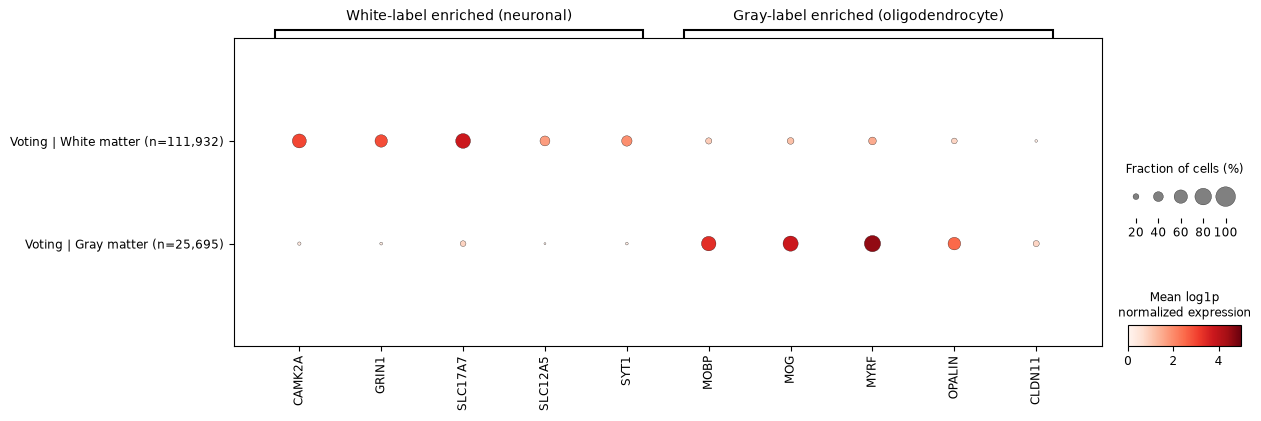

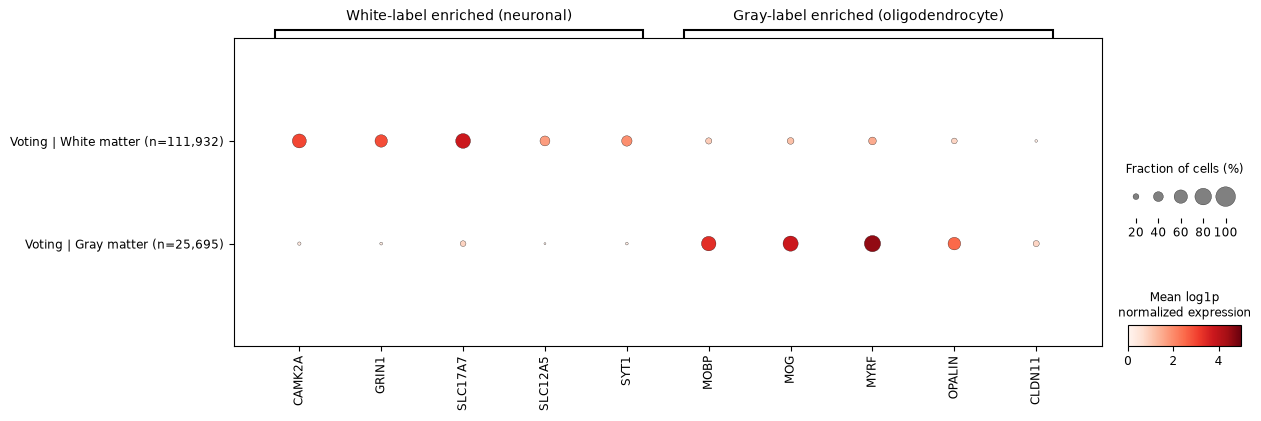

Saved /home/Data_Drive_8TB/kykim/0. Jupyter/CCF/BigBrain_voting_DEG_marker_dotplot.png


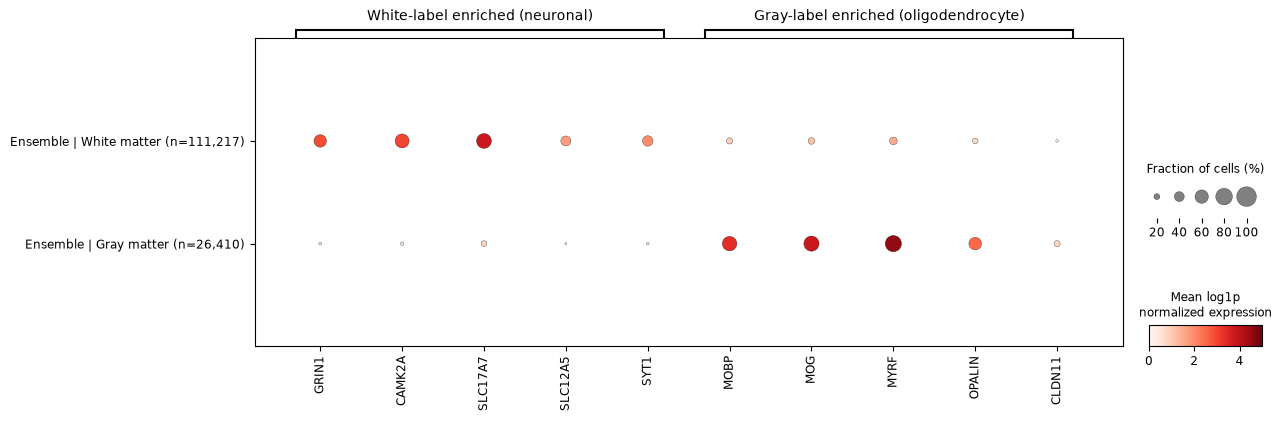

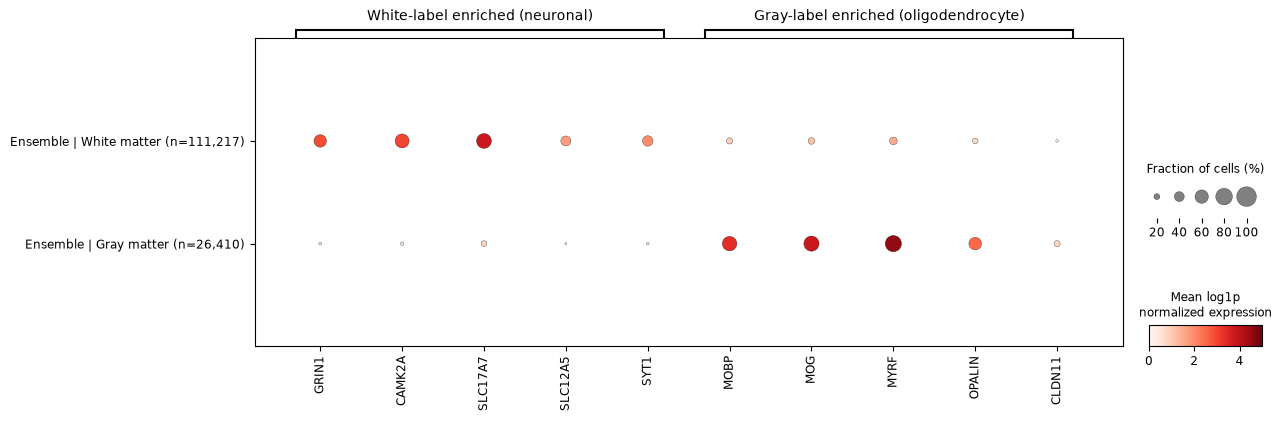

Saved /home/Data_Drive_8TB/kykim/0. Jupyter/CCF/BigBrain_ensemble_DEG_marker_dotplot.png


,method,marker_group,gene,log2fc_white_vs_gray,p_adj_bh,fraction_white,fraction_gray
0,voting,White-label enriched (neuronal),CAMK2A,3.6657,0.0,0.6346,0.0947
1,voting,White-label enriched (neuronal),GRIN1,3.6605,0.0,0.5455,0.0754
2,voting,White-label enriched (neuronal),SLC17A7,3.2084,0.0,0.6864,0.1942
3,voting,White-label enriched (neuronal),SLC12A5,3.0727,0.0,0.4039,0.0469
4,voting,White-label enriched (neuronal),SYT1,2.9516,0.0,0.4294,0.0713
5,voting,Gray-label enriched (oligodendrocyte),MOBP,-2.2279,0.0,0.2168,0.6685
6,voting,Gray-label enriched (oligodendrocyte),MOG,-1.9652,0.0,0.2400,0.7073
7,voting,Gray-label enriched (oligodendrocyte),MYRF,-1.9523,0.0,0.2900,0.7753
8,voting,Gray-label enriched (oligodendrocyte),OPALIN,-1.8360,0.0,0.1937,0.5551
9,voting,Gray-label enriched (oligodendrocyte),CLDN11,-1.6682,0.0,0.0687,0.2125


Adjusted p-values reported as 0 reflect numerical underflow, not an exact probability of zero.


In [2]:
import anndata as ad
import matplotlib.pyplot as plt
from IPython.display import display

# These are cell-type markers, not exclusive anatomical region markers.
marker_candidates = {
    "White-label enriched (neuronal)": ["CAMK2A", "GRIN1", "SLC17A7", "SLC12A5", "SYT1"],
    "Gray-label enriched (oligodendrocyte)": ["MOBP", "MOG", "MYRF", "OPALIN", "CLDN11"],
}
selected_rows = []
for method, deg in results.items():
    selected = {}
    for group, candidates in marker_candidates.items():
        missing = [g for g in candidates if g not in deg.index]
        if missing:
            raise ValueError(f"{method}: markers missing from DEG results: {missing}")
        frame = deg.loc[candidates].copy()
        sign = 1 if group.startswith("White") else -1
        eligible = (
            (frame["p_adj_bh"] < 0.05)
            & (sign * frame["log2fc_white_vs_gray"] > 1)
            & (frame[["fraction_white", "fraction_gray"]].max(axis=1) >= 0.10)
        )
        if not eligible.all():
            raise ValueError(f"{method}: markers failing DEG criteria: {frame.index[~eligible].tolist()}")
        frame = frame.sort_values("log2fc_white_vs_gray", ascending=sign < 0)
        selected[group] = frame.index.tolist()
        frame.insert(0, "marker_group", group)
        frame.insert(0, "method", method)
        selected_rows.append(frame.reset_index())

    genes = [gene for group in selected.values() for gene in group]
    keep = labels[f"{method}_region"].isin(["White matter", "Gray matter"]).to_numpy()
    region = labels.loc[keep, f"{method}_region"]
    counts_by_region = region.value_counts()
    categories = [f"{method.capitalize()} | {name} (n={counts_by_region[name]:,})"
                  for name in ["White matter", "Gray matter"]]
    row_labels = region.map({
        name: category for name, category in zip(["White matter", "Gray matter"], categories)
    })
    obs = pd.DataFrame(
        {"region": pd.Categorical(row_labels.to_numpy(), categories=categories, ordered=True)},
        index=adata.obs_names[keep],
    )
    var_indices = adata.var_names.get_indexer(genes)
    plot_data = ad.AnnData(
        X=lognorm[np.ix_(keep, var_indices)],
        obs=obs,
        var=pd.DataFrame(index=pd.Index(genes, name="gene")),
    )
    dot = sc.pl.dotplot(
        plot_data, selected, groupby="region", use_raw=False,
        expression_cutoff=0, mean_only_expressed=False, standard_scale=None,
        cmap="Reds", vmin=0, vmax=5, dot_max=1, var_group_rotation=0,
        figsize=(13, 4), return_fig=True,
    )
    dot.legend(colorbar_title="Mean log1p\nnormalized expression",
               size_title="Fraction of cells (%)")
    dot.make_figure()
    image = out_dir / f"BigBrain_{method}_DEG_marker_dotplot.png"
    dot.savefig(image, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved {image}")

selected_df = pd.concat(selected_rows, ignore_index=True)
selected_df.to_csv(out_dir / "BigBrain_voting_ensemble_selected_DEG_markers.csv", index=False)
display(selected_df[["method", "marker_group", "gene", "log2fc_white_vs_gray",
                     "p_adj_bh", "fraction_white", "fraction_gray"]].round(4))
print("Adjusted p-values reported as 0 reflect numerical underflow, not an exact probability of zero.")
